# 13 - Frozen sensors: finding stuck values before they find your metrics

> "Gateway G-14 sent the same reading for 19 hours on a Saturday. The dashboard was green. How
> many of our good numbers are made of frozen data?" - Kestrel facilities lead

The dashboard was green because nothing it checks had failed. A frozen gateway does not go
quiet. It keeps sending a reading every hour, on time, inside the meter's normal range, and
every one of those readings is a copy of the last value it relayed before it froze. The
missing-data check passes, the range check passes, the latency check passes. The only thing
wrong with the number is that it is not new.

The facilities lead's question splits into two sharper ones, and this notebook answers both
with numbers. The first is detection: can a rule simple enough to audit find stuck runs, and
what does it cost in false flags on flat lines that are innocent? The second is consequences:
if frozen readings sit in the training rows, the calibration window and the evaluation set,
what happens to the numbers the project reports (the model's MAE, the baselines' MAE, the
coverage and width of the conformal band), and does gating them out change any conclusion?
That second question is the one a thesis committee will ask in exactly these words: does
removing frozen windows change your results? The gate may improve accuracy, coverage only, or
neither, and we commit in advance to reporting whichever we find.

**What you will learn**

- How a frozen gateway corrupts a series, and how to simulate one with a ground-truth mask
  (`inject_stuck_runs`).
- The minimum-run-length rule in a handful of numpy lines, with a float tolerance, scored
  by precision and recall against the truth.
- Why legitimate flat lines (a VM saturated at exactly 100%, a meter that rounds to whole kWh
  on a quiet night) make short run lengths expensive, and which guards help.
- What frozen rows do to walk-forward MAE, coverage and width under three pipelines (raw,
  gated, oracle-gated), measured against the observed values and against the true ones.
- A gate policy for training, calibration, evaluation and live monitoring.

**Where we are in the series.** Notebook 12 filled in the benchmark table with CQR bands
around local, pre-trained and ensemble forecasters; this notebook asks whether numbers like
those survive dirty data. It reuses notebook 11's walk-forward protocol unchanged and the same CQR
recipe as notebook 12, without its quantile-crossing repair (on the same data that moves
numbers only in the third decimal), and leans on Part I for the corrected quantile (notebook 02), exchangeability
(notebook 03) and CQR itself (notebook 05). Notebook 14 turns band edges into alarm limits and
finds that they catch a freeze only where the series has a rhythm strong enough to contradict
the frozen value: often on the building, no better than chance on the bursty VM, because a
next-hour forecaster follows the frozen value and its band follows the forecaster. Catching
freezes everywhere is this notebook's job, which is why the two detectors belong side by side
in production.

## 1. What a frozen sensor looks like

Kestrel's meters do not talk to the data platform directly. Each one reports to a gateway, a
small box on the building network that collects readings and forwards them on a schedule.
When the link between meter and gateway drops, or the gateway's firmware hangs, many gateways
do not send "no data". They send the last value in their buffer, again and again, until
somebody power-cycles the box. The cloud side has the same failure in different clothes: a
monitoring agent stalls and its exporter keeps serving the cached metric. Either way the
fingerprint is the same, a run of identical readings, often identical to the last decimal, in
a series that otherwise never repeats itself exactly.

We will call that a **stuck run** (or frozen run): consecutive identical readings produced by
a frozen sensor or gateway. Anyone who has cleaned public meter collections such as Building
Data Genome 2 has met them; here we manufacture them, because a simulation hands us something
no real project ever has: the list of which readings were frozen.

The simulators and protocol functions below are copied verbatim from the Part II shared code.
Read the docstring of `simulate_vm_cpu` before moving on: it promises that a saturated VM
reports exactly 100.0 several readings in a row, "a legitimate flat line that a naive
stuck-sensor rule will mistake for a frozen gateway". Section 3 holds it to that promise.

In [1]:
import math
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import HistGradientBoostingRegressor  # the model inside quantile_gbm
from threadpoolctl import threadpool_limits                 # installed with scikit-learn

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 140)
RANDOM_SEED = 20260707
ALPHA = 0.10   # the project's 90% band

# Series palette: blue = data, green = covered/healthy, amber = calibration/warning,
# red = missed/fault/naive, gray = reference, purple = alternative method.
BLUE, GREEN, AMBER, RED, GRAY, PURPLE = (
    "#2563EB", "#059669", "#F59E0B", "#DC2626", "#6B7280", "#7C3AED",
)

# This notebook fits about 160 small models. HistGradientBoosting spreads each fit over
# every CPU core; on tables this small the coordination costs more than it saves, and on a
# busy laptop it can make every fit several times slower. One thread is plenty here, and
# it does not change a single prediction. (Keep the returned object: it holds the limit.)
THREAD_LIMIT = threadpool_limits(1, user_api="openmp")

In [2]:
# Copied verbatim from the Part II shared code: the two Kestrel simulators.
def simulate_building_load(n_days, seed, start="2016-01-01", base_kwh=120.0,
                           occupied_kwh=180.0, hvac_kwh_per_deg=6.0, noise_frac=0.06,
                           shift_day=None, shift_frac=0.0):
    """Simulate an hourly electricity meter for one Kestrel office building.

    What the simulator bakes in (and what later notebooks test against):
    - A daily occupancy profile: busy 08:00-18:00 on weekdays, quiet nights and weekends.
      That is why 'same hour yesterday' and 'same hour last week' are strong baselines.
    - Heating and cooling: load rises when the outdoor temperature leaves a comfort zone,
      and the temperature follows the seasons, so summer and winter behave differently.
    - Noise that is autocorrelated (a busy morning tends to stay busy) and larger when the
      building is occupied. Residuals are neither independent nor equal-sized.
    - Optional regime change: from day `shift_day` on, the load level is multiplied by
      (1 + shift_frac) - a new tenant, a retrofit. Notebook 15 uses it to break calibration.

    Returns a DataFrame indexed by hourly timestamp with columns `load_kwh` and `temp_c`.
    """
    rng = np.random.default_rng(seed)
    idx = pd.date_range(start, periods=24 * n_days, freq="h")
    n = len(idx)
    hour = idx.hour.to_numpy()
    dow = idx.dayofweek.to_numpy()
    doy = idx.dayofyear.to_numpy()

    # Weather: seasons + a daily cycle + persistent anomalies (a cold week stays cold).
    anomaly = np.zeros(n)
    shocks = rng.normal(0.0, 0.6, size=n)
    for i in range(1, n):
        anomaly[i] = 0.97 * anomaly[i - 1] + shocks[i]
    temp = 12.0 - 10.0 * np.cos(2 * np.pi * (doy - 15) / 365.25) \
        + 4.0 * np.sin(2 * np.pi * (hour - 9) / 24) + anomaly

    # Occupancy: weekdays 08-18, with half-occupied shoulder hours at 07 and 18.
    occupied = ((dow < 5) & (hour >= 8) & (hour < 18)).astype(float)
    shoulder = ((dow < 5) & ((hour == 7) | (hour == 18))).astype(float) * 0.5
    occ = occupied + shoulder

    hvac = hvac_kwh_per_deg * (1.3 * np.maximum(temp - 22.0, 0.0)
                               + np.maximum(16.0 - temp, 0.0)) * (0.4 + 0.6 * occ)
    mean_load = base_kwh + occupied_kwh * occ + hvac

    # Autocorrelated, occupancy-dependent multiplicative noise.
    ar = np.zeros(n)
    z = rng.normal(0.0, 1.0, size=n)
    for i in range(1, n):
        ar[i] = 0.8 * ar[i - 1] + math.sqrt(1 - 0.8 ** 2) * z[i]
    load = mean_load * (1.0 + noise_frac * (1.0 + occ) * ar)

    if shift_day is not None:
        load = np.where(np.arange(n) >= 24 * shift_day, load * (1.0 + shift_frac), load)
    return pd.DataFrame({"load_kwh": np.maximum(load, 0.0), "temp_c": temp}, index=idx)


def simulate_vm_cpu(n_days, seed, start="2019-01-01", base_pct=22.0, daily_amp=8.0,
                    bursts_per_day=5.0, n_redeploys=2):
    """Simulate 5-minute average CPU utilisation (%) for one Kestrel virtual machine.

    What the simulator bakes in (and what later notebooks test against):
    - A weak daily rhythm (busier in business hours) on top of a level that jumps when the
      service is redeployed. The jumps are sudden and unannounced.
    - Bursts: spikes arriving at random times (batch jobs, traffic surges) that decay over
      a few readings. They make the series bursty - the reason simple baselines are so hard
      to beat on cloud data.
    - Readings are clipped to [0, 100]. During heavy bursts the VM saturates and reports
      exactly 100.0 several readings in a row - a legitimate flat line that a naive
      stuck-sensor rule will mistake for a frozen gateway (notebook 13).

    Returns a DataFrame indexed by 5-minute timestamp with column `cpu_pct`.
    """
    rng = np.random.default_rng(seed)
    steps_per_day = 288
    n = steps_per_day * n_days
    idx = pd.date_range(start, periods=n, freq="5min")
    hour = idx.hour.to_numpy() + idx.minute.to_numpy() / 60.0

    # Level that jumps at redeployments.
    level = np.full(n, base_pct)
    for when in np.sort(rng.integers(steps_per_day * 2, n, size=n_redeploys)):
        level[when:] = level[when:] * rng.lognormal(0.0, 0.35)

    daily = daily_amp * np.clip(np.sin(np.pi * (hour - 7) / 12), 0.0, None)

    # Bursts: random arrivals, random heights, exponential decay over a few readings.
    burst = np.zeros(n)
    n_bursts = rng.poisson(bursts_per_day * n_days)
    for start_step, height, decay in zip(rng.integers(0, n, size=n_bursts),
                                         rng.exponential(35.0, size=n_bursts),
                                         rng.uniform(2.0, 10.0, size=n_bursts)):
        span = np.arange(start_step, min(start_step + int(6 * decay), n))
        burst[span] += height * np.exp(-(span - start_step) / decay)

    ar = np.zeros(n)
    z = rng.normal(0.0, 1.0, size=n)
    for i in range(1, n):
        ar[i] = 0.6 * ar[i - 1] + z[i]
    cpu = level + daily + burst + 2.5 * ar
    return pd.DataFrame({"cpu_pct": np.clip(cpu, 0.0, 100.0)}, index=idx)

In [3]:
# Copied verbatim from the Part II shared code: the leakage-safe table, the shared quantile
# model, notebook 11's walk-forward blocks, the metrics and notebook 02's corrected quantile.
def make_direct_table(y, h, period, exog=None):
    """Turn a series into a supervised table for forecasting h steps ahead.

    One row per forecast origin t. Every feature uses only values known at time t
    (y[t], y[t-1], ...); the target is y[t + h]. `period` is the number of steps per day
    (24 for hourly meters, 288 for 5-minute CPU). Requires h <= period, so that 'same time
    yesterday' (relative to the target) is already observed at the origin.

    The four simple baselines and the past-percentile reference band are columns of this
    table, computed with exactly the same no-peeking rule as the model features.
    """
    assert h <= period, "h must not exceed one day, or 'same time yesterday' is in the future"
    v = y.to_numpy(dtype=float)
    n = len(v)
    target_pos = np.arange(n) + h

    def at(offset):
        """Value at position (t + offset) for every origin t; NaN when out of range."""
        pos = np.arange(n) + offset
        out = np.full(n, np.nan)
        ok = (pos >= 0) & (pos < n)
        out[ok] = v[pos[ok]]
        return out

    same_time_past_days = np.column_stack([at(h - k * period) for k in range(1, 15)])
    table = pd.DataFrame({
        "last_value": v,
        "mean_last_day": pd.Series(v).rolling(period).mean().to_numpy(),
        "same_time_yesterday": same_time_past_days[:, 0],
        "same_time_last_week": same_time_past_days[:, 6],
        "median_14d_same_time": np.median(same_time_past_days, axis=1),
        "p05_14d_same_time": np.percentile(same_time_past_days, 5, axis=1),
        "p95_14d_same_time": np.percentile(same_time_past_days, 95, axis=1),
    }, index=y.index)
    target_time = y.index + h * (y.index[1] - y.index[0])
    table["target_hour"] = target_time.hour + target_time.minute / 60.0
    table["target_dow"] = target_time.dayofweek
    if exog is not None:
        # Treated as a forecast known in advance (e.g. tomorrow's weather forecast).
        e = exog.to_numpy(dtype=float)
        exog_at_target = np.full(n, np.nan)
        ok = target_pos < n
        exog_at_target[ok] = e[target_pos[ok]]
        table["exog_at_target"] = exog_at_target
    table["target"] = at(h)
    table["target_time"] = target_time
    return table.dropna().copy()


BASELINES = ["last_value", "same_time_yesterday", "same_time_last_week", "median_14d_same_time"]
MODEL_FEATURES = ["last_value", "mean_last_day", "same_time_yesterday", "same_time_last_week",
                  "median_14d_same_time", "target_hour", "target_dow"]


def quantile_gbm(q, seed=20260707):
    """Gradient-boosted quantile model used by every Part II notebook.

    Small and fast on purpose (each fit takes well under a second). early_stopping=False
    matters: scikit-learn's automatic early stopping holds out a RANDOM 10% of rows, which
    on time-ordered data quietly lets the model peek at its own future.
    """
    from sklearn.ensemble import HistGradientBoostingRegressor
    return HistGradientBoostingRegressor(loss="quantile", quantile=q, max_iter=60,
                                         learning_rate=0.15, max_leaf_nodes=15,
                                         early_stopping=False, random_state=seed)


def walk_forward_blocks(n_rows, first_test_row, block_len, cal_len, h):
    """Yield (train_rows, cal_rows, test_rows) position arrays for rolling-origin evaluation.

    Rows are forecast origins in time order. For each block starting at row s:
    - test rows are [s, s + block_len): forecasts issued during the block;
    - calibration rows are the cal_len origins whose targets are all observed by time s,
      i.e. rows [s - h - cal_len + 1, s - h];
    - training rows end h rows before calibration starts, so no training target overlaps
      the calibration period (a purge of h rows).
    The model is re-fitted before every block on the training rows only.
    """
    s = first_test_row
    while s < n_rows:
        cal_end = s - h + 1
        cal_start = cal_end - cal_len
        train_end = cal_start - h
        assert train_end > 0, "not enough history before the first block"
        yield (np.arange(0, train_end), np.arange(cal_start, cal_end),
               np.arange(s, min(s + block_len, n_rows)))
        s += block_len


def interval_score(y, lo, hi, alpha):
    """Gneiting-Raftery interval score of a central (1 - alpha) band; lower is better.

    Width, plus a penalty of 2/alpha per unit of distance for every observation that lands
    outside the band. A band that is too narrow pays in misses; a band that is too wide
    pays in width. Averaged over observations.
    """
    y, lo, hi = np.asarray(y), np.asarray(lo), np.asarray(hi)
    return float(np.mean((hi - lo)
                         + (2.0 / alpha) * np.maximum(lo - y, 0.0)
                         + (2.0 / alpha) * np.maximum(y - hi, 0.0)))


def band_report(y, point, lo, hi, alpha):
    """MAE of the point forecast, plus coverage, mean width and interval score of the band."""
    y, point, lo, hi = map(np.asarray, (y, point, lo, hi))
    return {
        "MAE": float(np.mean(np.abs(y - point))),
        "coverage": float(np.mean((y >= lo) & (y <= hi))),
        "width": float(np.mean(hi - lo)),
        "interval_score": interval_score(y, lo, hi, alpha),
    }


def corrected_quantile(scores, alpha):
    """The corrected quantile from notebook 02 (finite-sample, slightly conservative)."""
    n = len(scores)
    q_level = math.ceil((n + 1) * (1 - alpha)) / n
    assert q_level <= 1.0, "calibration window too short for this alpha (field guide S1)"
    return float(np.quantile(scores, q_level, method="higher"))

Now the one new ingredient. `inject_stuck_runs` freezes a clean series the way a failing
gateway does, and returns the ground truth alongside the damage. Two design decisions are
worth reading in the docstring. The reading just before a freeze is genuine (it is the value
the gateway froze on), so an episode of L frozen readings shows up as a flat line of L + 1
identical values; the mask marks only the L copies. And episodes never touch, so each flat
line is exactly one failure.

We give each family a deliberately badly behaved device. The building gateway freezes 80
times in two years, each time for 2 to 30 hours. The VM's monitoring agent freezes 30 times in
30 days, each time for 3 to 36 readings (15 minutes to 3 hours). That is about one frozen
reading in thirteen for the building and one in fifteen for the VM, far worse than a typical
device. Real fleets are mostly clean with a few terrible members; every effect measured
in section 4 grows with the share of frozen readings, so remember this dial when you read it.

In [4]:
def inject_stuck_runs(y, seed, n_runs, min_len, max_len):
    """Freeze a series the way a failing gateway does: it keeps repeating its last value.

    A frozen gateway does not go silent. It keeps sending a reading on schedule, and every
    reading is a copy of the last value it relayed before it froze. Nothing is missing,
    nothing is late, nothing is out of range - which is why the data-quality dashboard
    stays green.

    For each of `n_runs` episodes we draw a length L between `min_len` and `max_len`
    (inclusive) and a random start s, then overwrite readings s, ..., s + L - 1 with the
    reading at s - 1, the last genuine value. Episodes never overlap or touch, so each one
    appears as a flat line of L + 1 identical readings of which only the last L are frozen.

    Returns (observed, frozen): the observed series (same index and name as `y`) and a
    boolean array that is True exactly at the frozen readings - the ground truth that no
    real project ever gets to see.
    """
    rng = np.random.default_rng(seed)
    values = y.to_numpy(dtype=float).copy()
    frozen = np.zeros(len(values), dtype=bool)
    assert n_runs * (max_len + 3) < len(values) / 2, "too many episodes for this series"
    placed = 0
    while placed < n_runs:
        length = int(rng.integers(min_len, max_len + 1))
        start = int(rng.integers(2, len(values) - length))
        if frozen[start - 2: start + length + 1].any():   # would overlap or touch: redraw
            continue
        values[start:start + length] = values[start - 1]  # repeat the last genuine reading
        frozen[start:start + length] = True
        placed += 1
    return pd.Series(values, index=y.index, name=y.name), frozen


def episodes(mask):
    """Start positions and lengths of the stretches where a boolean mask is True."""
    edges = np.diff(np.concatenate([[0], mask.astype(int), [0]]))
    starts = np.flatnonzero(edges == 1)
    return starts, np.flatnonzero(edges == -1) - starts


b = simulate_building_load(730, seed=RANDOM_SEED)
v = simulate_vm_cpu(30, seed=RANDOM_SEED)
load_true, cpu_true = b["load_kwh"], v["cpu_pct"]

# A badly behaved building gateway: 80 freezes in two years, 2 to 30 hours each.
load_obs, load_frozen = inject_stuck_runs(load_true, seed=RANDOM_SEED + 1,
                                          n_runs=80, min_len=2, max_len=30)
# A badly behaved VM monitoring agent: 30 freezes in 30 days, 15 minutes to 3 hours each.
cpu_obs, cpu_frozen = inject_stuck_runs(cpu_true, seed=RANDOM_SEED + 2,
                                        n_runs=30, min_len=3, max_len=36)

for name, obs, true, frozen, unit, rated_max in [
        ("building", load_obs, load_true, load_frozen, "kWh", 1000.0),
        ("VM", cpu_obs, cpu_true, cpu_frozen, "% CPU", 100.0)]:
    starts, lengths = episodes(frozen)
    miss = np.abs(obs - true).to_numpy()[frozen]
    # The three checks a typical data-quality dashboard runs. Frozen data passes all three.
    n_missing = int(obs.isna().sum())
    n_out_of_range = int(((obs < 0) | (obs > rated_max)).sum())
    n_off_schedule = int((obs.index.to_series().diff().dropna() != obs.index[1] - obs.index[0]).sum())
    print(f"{name}: {frozen.sum():,} of {len(obs):,} readings frozen ({frozen.mean():.1%}) in "
          f"{len(starts)} episodes of {lengths.min()}-{lengths.max()} readings "
          f"(median {np.median(lengths):.0f})")
    print(f"   a frozen reading misses the truth by {miss.mean():.1f} {unit} on average, "
          f"worst {miss.max():.1f} {unit}; median reading {np.median(true):.1f} {unit}")
    print(f"   dashboard checks -> missing: {n_missing}, out of range: {n_out_of_range}, "
          f"off schedule: {n_off_schedule}")

building: 1,360 of 17,520 readings frozen (7.8%) in 80 episodes of 2-30 readings (median 18)
   a frozen reading misses the truth by 87.7 kWh on average, worst 313.8 kWh; median reading 149.7 kWh
   dashboard checks -> missing: 0, out of range: 0, off schedule: 0
VM: 590 of 8,640 readings frozen (6.8%) in 30 episodes of 4-35 readings (median 22)
   a frozen reading misses the truth by 5.7 % CPU on average, worst 49.4 % CPU; median reading 49.8 % CPU
   dashboard checks -> missing: 0, out of range: 0, off schedule: 0


The building gateway froze 1,360 of 17,520 hourly readings (7.8%) in 80 episodes lasting
2 to 30 hours, median 18. A frozen reading misses what the building actually used by 87.7 kWh
on average, against a median reading of 149.7 kWh. That is not a rounding error; it is a
different number, because a freeze that begins at 06:00 keeps reporting the night load
straight through the busiest hours of the day. The worst single frozen reading is off by
313.8 kWh. The VM agent froze 590 of 8,640 readings (6.8%) in 30 episodes of 4 to 35
readings; a typical frozen reading is off by 5.7 points of CPU and the worst by 49.4, a burst
the agent never reported.

Now the line that answers the second sentence of the facilities lead's complaint: missing 0,
out of range 0, off schedule 0, for both series. Every check the dashboard runs passes on data
that is wrong about one reading in thirteen (building) to fifteen (VM). That is not a bug in
the dashboard. It was never designed to ask whether a value is new.

Building: 20 frozen hours from Sat 23 Jul 2016 10:00: true value 117.3 to 153.9 while the report stayed at 127.8; largest gap 26.1
VM: 35 frozen readings (175 min) from Wed 23 Jan 00:15: true value 42.9 to 54.8 while the report stayed at 46.5; largest gap 8.4


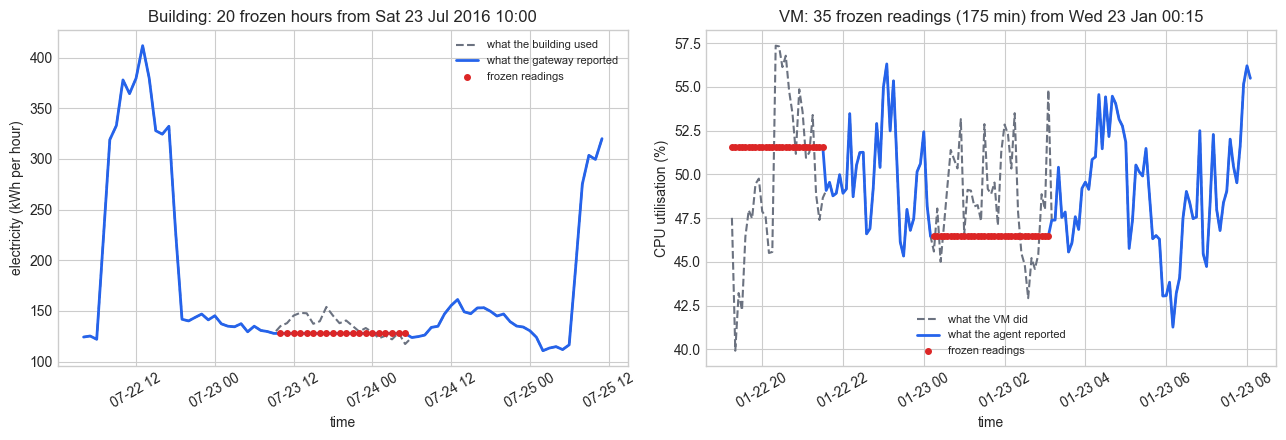

In [5]:
# The closest our simulated gateway comes to G-14: the Saturday episode nearest 19 hours.
st_b, len_b = episodes(load_frozen)
saturday = np.flatnonzero(load_obs.index[st_b].dayofweek == 5)
k_b = saturday[np.argmin(np.abs(len_b[saturday] - 19))]
# For the VM, the longest episode that is NOT frozen at the 100% limit (section 3 explains why).
st_v, len_v = episodes(cpu_frozen)
below_limit = np.flatnonzero(cpu_obs.to_numpy()[st_v] < 100.0)
k_v = below_limit[np.argmax(len_v[below_limit])]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
panels = [
    (axes[0], load_obs, load_true, load_frozen, st_b[k_b], len_b[k_b], 30,
     "what the building used", "what the gateway reported", "electricity (kWh per hour)",
     f"Building: {len_b[k_b]} frozen hours from {load_obs.index[st_b[k_b]]:%a %d %b %Y %H:%M}"),
    (axes[1], cpu_obs, cpu_true, cpu_frozen, st_v[k_v], len_v[k_v], 60,
     "what the VM did", "what the agent reported", "CPU utilisation (%)",
     f"VM: {len_v[k_v]} frozen readings ({5 * len_v[k_v]} min) from "
     f"{cpu_obs.index[st_v[k_v]]:%a %d %b %H:%M}"),
]
for ax, obs, true, frozen, s, n_frozen, pad, true_label, obs_label, ylabel, title in panels:
    during = slice(s, s + n_frozen)
    print(f"{title}: true value {true.iloc[during].min():.1f} to {true.iloc[during].max():.1f} while "
          f"the report stayed at {obs.iloc[s]:.1f}; largest gap {np.abs(obs - true).iloc[during].max():.1f}")
    win = slice(s - pad, s + n_frozen + pad)
    t, fz = obs.index[win], frozen[win]
    ax.plot(t, true.iloc[win], color=GRAY, linestyle="--", linewidth=1.5, label=true_label)
    ax.plot(t, obs.iloc[win], color=BLUE, linewidth=2, label=obs_label)
    ax.scatter(t[fz], obs.iloc[win][fz], color=RED, s=16, zorder=3, label="frozen readings")
    ax.set_title(title)
    ax.set_xlabel("time")
    ax.set_ylabel(ylabel)
    ax.tick_params(axis="x", rotation=30)
    ax.legend(loc="best", fontsize=8)
plt.tight_layout()
plt.show()

The left panel is the closest our gateway comes to G-14: 20 frozen hours from Saturday
23 July 2016 at 10:00. Notice how little is visibly wrong. On a quiet summer Saturday the
building drifts between 117.3 and 153.9 kWh, the frozen report of 127.8 kWh sits inside that
range, and the gap between the blue line and the gray truth never exceeds 26.1 kWh. A freeze on a
weekend is nearly invisible precisely because nothing much was happening, which is how a
19-hour freeze survives a green dashboard. A freeze that starts on a weekday morning would be
a different story: the frozen line would miss the whole occupancy ramp, the climb visible on
the Friday at the left of the panel, and the 87.7 kWh average miss above is the blend of both
kinds.

The right panel shows the VM agent's longest episode below the 100% limit, 35 readings (175
minutes) from Wednesday 23 January at 00:15, and, at the left edge, an earlier episode from the
evening before: this agent froze twice in one night. The real CPU keeps jittering between 42.9%
and 54.8% underneath a report stuck at 46.5%, never more than 8.4 points away, which is why
nothing about the flat line looks alarming on its own. What
neither panel can show is how a freeze looks without the gray line, and that is the real
situation: exactly like the blue line, on time, in range and plausible.

## 2. The minimum-run-length rule

The fingerprint suggests the detector. In words: a reading is suspicious if it belongs to a
flat run, a stretch of consecutive readings each equal to the one before it, and the run is at
least L readings long. We flag the repeats, not the first reading of the run, because the
first one is genuine; it is the value the gateway froze on. That is the
**minimum-run-length rule**, and its single dial L trades missed freezes (L too long) against
innocent flat lines (L too short).

The same rule in symbols, after its twin in words. Call a stretch of readings $y_a, \dots, y_b$
a run when every step inside it is flat, $|y_i - y_{i-1}| \le \tau$ for $a < i \le b$, and the
stretch cannot be extended at either end. Here $y_i$ is the reading at step $i$, $a$ and $b$
are the first and last steps of the run, and $\tau$ is a tolerance. The rule flags every
reading $y_t$ with $a < t \le b$ in a run whose length $b - a + 1$ is at least $L$.

The tolerance $\tau$ deserves a sentence. Copies of the same float are bit-identical, so a
purely simulated freeze would be caught with exact equality. Real pipelines are not that
polite: a unit conversion, a resampling step or a CSV round trip can turn one value into two
that print the same and differ in the sixteenth digit. A tolerance of `1e-6` absorbs that
noise. It is not a licence to call a slow genuine drift "flat": because each step is compared
with the one before, a large tolerance would chain a gentle ramp into one long false run.

The implementation needs no loop. `np.diff` marks every flat step, a cumulative sum of the
"value moved" markers labels the runs 0, 1, 2, ... in time order, and `np.bincount` counts
how many readings carry each label, which is each run's length. That is run-length encoding
in four lines.

In [6]:
def flag_stuck_runs(values, min_run, tol=1e-6):
    """Minimum-run-length rule: flag readings that repeat inside a flat run of >= min_run readings.

    A run is a maximal stretch of consecutive readings, each within `tol` of the one before.
    The first reading of a run is genuine (it is the value the gateway froze on), so only
    the repeats are flagged. `tol` absorbs floating-point noise from unit conversions and
    resampling; it is not a licence to call a slow genuine drift 'flat'.
    """
    v = np.asarray(values, dtype=float)
    repeats_previous = np.abs(np.diff(v)) <= tol             # step i -> i+1 is flat
    starts_run = np.concatenate([[True], ~repeats_previous])  # a run starts wherever the value moves
    run_id = np.cumsum(starts_run) - 1                        # label runs 0, 1, 2, ... in time order
    run_length = np.bincount(run_id)[run_id]                  # every reading learns its run's length
    return (run_length >= min_run) & ~starts_run              # in a long run, and not its first reading


# A ten-second test: a run of four 7.0s, a pair of 3.0s, and a float trap at the end.
toy = np.array([5.0, 7.0, 7.0, 7.0, 7.0, 3.0, 3.0, 8.0, 0.1 + 0.2, 0.3, 0.3])
print(f"0.1 + 0.2 is stored as {0.1 + 0.2!r}; equal to 0.3? {0.1 + 0.2 == 0.3}")
pd.DataFrame({"reading": toy,
              "flag, L = 2": flag_stuck_runs(toy, 2),
              "flag, L = 3": flag_stuck_runs(toy, 3),
              "flag, L = 3, tol = 0": flag_stuck_runs(toy, 3, tol=0.0)}).T

0.1 + 0.2 is stored as 0.30000000000000004; equal to 0.3? False


,0,1,2,3,4,5,6,7,8,9,10
reading,5.0,7.0,7.0,7.0,7.0,3.0,3.0,8.0,0.3,0.3,0.3
"flag, L = 2",False,False,True,True,True,False,True,False,False,True,True
"flag, L = 3",False,False,True,True,True,False,False,False,False,True,True
"flag, L = 3, tol = 0",False,False,True,True,True,False,False,False,False,False,False


Read the flag rows against the readings. The four 7.0s (positions 1 to 4) form one run of
length 4: the first 7.0 is genuine and its three repeats are flagged, at L = 2 and at L = 3.
The two 3.0s form a run of length 2: flagged at L = 2, cleared at L = 3. The float trap is the
last three readings. They all print as 0.3, but the first is stored as 0.30000000000000004, so
with `tol = 0` they split into a run of one and a run of two, and the L = 3 rule misses them.
With the default tolerance they are one run of three, and both repeats are flagged. One
keyword argument removes a whole class of silent misses.

In [7]:
def precision_recall(flags, truth):
    """Precision: share of flagged readings truly frozen. Recall: share of frozen readings flagged."""
    caught = int((flags & truth).sum())
    return {"flagged": int(flags.sum()),
            "precision": caught / flags.sum() if flags.sum() else np.nan,
            "recall": caught / truth.sum()}


rows = []
for family, obs, truth, minutes_per_reading in [("building", load_obs, load_frozen, 60),
                                                ("VM", cpu_obs, cpu_frozen, 5)]:
    for L in (2, 3, 4, 6, 12, 24):
        rows.append({"family": family, "L": L, "flat for (minutes)": L * minutes_per_reading,
                     **precision_recall(flag_stuck_runs(obs, L), truth)})
pr_grid = pd.DataFrame(rows).set_index(["family", "L"])
pr_grid.round(3)

flat for (minutes)  flagged  precision  recall
family   L                                                 
building 2                  120     1360      1.000   1.000
         3                  180     1360      1.000   1.000
         4                  240     1356      1.000   0.997
         6                  360     1353      1.000   0.995
         12                 720     1201      1.000   0.883
         24                1440      676      1.000   0.497
VM       2                   10      663      0.890   1.000
         3                   15      652      0.905   1.000
         4                   20      638      0.925   1.000
         6                   30      612      0.958   0.993
         12                  60      541      1.000   0.917
         24                 120      406      1.000   0.688

On the float building series the rule is perfect at short run lengths: precision 1.000 at
every L, because a meter that reports many decimals never repeats itself by accident, so every
flag is a freeze. Recall is 1.000 at L = 2 and 3, then falls as L outgrows the shortest
freezes: 0.997 at L = 4 (an episode of two frozen readings is a flat line of three, too short
to trigger), 0.883 at L = 12 and 0.497 at L = 24, where only freezes longer than a full day
are caught. The `flat for (minutes)` column is the same L in time units: L readings of an
hourly meter cover L hours.

The VM tells a different story. At L = 2 the rule catches every frozen reading (recall 1.000),
but only 0.890 of its 663 flags are real: 73 flags land on readings that were never frozen.
Precision climbs with L and reaches 1.000 at L = 12, by which point recall has dropped to 0.917,
and at L = 24 to 0.688. No single L gives the VM both. Precision is the number the on-call
engineer feels (how many flags are wasted trips) and recall the number the forecaster feels
(how much frozen data still reaches the model); section 3 finds out who the 73 innocents are.

## 3. Flat lines that are innocent

The rule's weakness is in its premise: "a healthy series never repeats itself exactly". Two
kinds of healthy data break that premise all the time. A machine at a physical limit reports
the limit: a VM at full load reports 100.0, a meter on a switched-off feeder reports 0.0. And a
sensor with coarse resolution repeats itself whenever the true value moves less than one step:
a meter that reports whole kWh repeats on a quiet night when the load drifts by a few tenths.
Both produce flat lines that look, to the minimum-run-length rule, exactly like a freeze.

We test both on clean data, where every flag is by construction a false alarm: first the
simulator's promise about saturation, then a meter that rounds the same building's load to
whole kWh.

In [8]:
# The simulator's promise, tested: how often does a HEALTHY VM report exactly 100.0?
at_limit = cpu_true.to_numpy() == 100.0
sat_starts, sat_lengths = episodes(at_limit)
flat_steps = np.abs(np.diff(cpu_true.to_numpy())) <= 1e-6
print(f"healthy VM: {at_limit.mean():.1%} of readings are exactly 100.0, in {len(sat_lengths)} "
      f"saturation runs; {(sat_lengths >= 3).sum()} last 3+ readings, the longest "
      f"{sat_lengths.max()} ({5 * sat_lengths.max()} min)")
print(f"healthy VM: flat steps anywhere other than at 100.0: {int((flat_steps & ~at_limit[1:]).sum())}")

# The same healthy building, read by a meter that reports whole kWh.
load_rounded = load_true.round()
innocent_2 = flag_stuck_runs(load_rounded, 2)
t_flag = load_rounded.index[innocent_2]
occupied = (t_flag.dayofweek < 5) & (t_flag.hour >= 7) & (t_flag.hour <= 18)
print(f"rounded meter, L = 2: {innocent_2.sum()} innocent flags, {1 - occupied.mean():.0%} of them "
      f"outside occupied hours; median load at a flag {np.median(load_rounded[innocent_2]):.0f} kWh "
      f"vs {np.median(load_rounded):.0f} kWh overall")

# Count both units (field guide §21): flagged readings, and events - one innocent flat line is
# one page for the on-call engineer however many of its readings get flagged.
rows = []
for L in (2, 3, 4, 5, 6, 8, 12):
    row = {"L": L}
    for name, series, days in [("VM", cpu_true, 30), ("meter", load_rounded, 730)]:
        flags = flag_stuck_runs(series, L)
        row[f"{name}: flags"] = int(flags.sum())
        row[f"{name}: flags per day"] = flags.sum() / days
        row[f"{name}: events per day"] = len(episodes(flags)[0]) / days
    rows.append(row)
innocent = pd.DataFrame(rows).set_index("L")
innocent.round(3)

healthy VM: 1.5% of readings are exactly 100.0, in 44 saturation runs; 20 last 3+ readings, the longest 11 (55 min)
healthy VM: flat steps anywhere other than at 100.0: 0
rounded meter, L = 2: 843 innocent flags, 91% of them outside occupied hours; median load at a flag 134 kWh vs 150 kWh overall


,VM: flags,VM: flags per day,VM: events per day,meter: flags,meter: flags per day,meter: events per day
L,,,,,,
2,84,2.800,1.067,843,1.155,1.078
3,72,2.400,0.667,110,0.151,0.074
4,58,1.933,0.433,6,0.008,0.003
5,40,1.333,0.233,0,0.000,0.000
6,36,1.200,0.200,0,0.000,0.000
8,10,0.333,0.033,0,0.000,0.000
12,0,0.000,0.000,0,0.000,0.000


The docstring keeps its promise. A healthy VM reports exactly 100.0 on 1.5% of its readings,
in 44 saturation runs; 20 of them last three readings or more and the longest lasts 11
readings (55 minutes). There is not a single flat step anywhere else in the healthy series, so
every false flag on the VM is saturation: 84 of them at L = 2 (in the contaminated copy a few
saturation readings were overwritten by freezes, hence the 73 of section 2), 58 at L = 4, still
10 at L = 8 and none at L = 12.

The rounded meter is worse at short L and better at long L. At L = 2 it raises 843 innocent
flags, 91% of them outside occupied hours, where the median load at a flag is 134 kWh against
150 kWh overall: quiet nights and weekends, when the true load moves by less than half a kWh
from one hour to the next. The count collapses to 110 at L = 3, 6 at L = 4 and zero from L = 5
on. Read the per-day columns as false-alarm rates, because that is what they become in
production, and read them in both units (field guide §21): flagged readings are what the rule
produces, events (one innocent flat line, however many of its readings get flagged) are what
the on-call engineer gets paged for. At L = 2 a fleet of 3,000 such meters would flag about
3,500 healthy readings a day in about 3,200 separate events, since most quiet-night repeats
are pairs. A fleet of 3,000 VMs would flag about 8,400 readings but in only about 3,200 events
(1.067 a day per VM against 2.800 flags), because one saturation run is one event and several
flags.

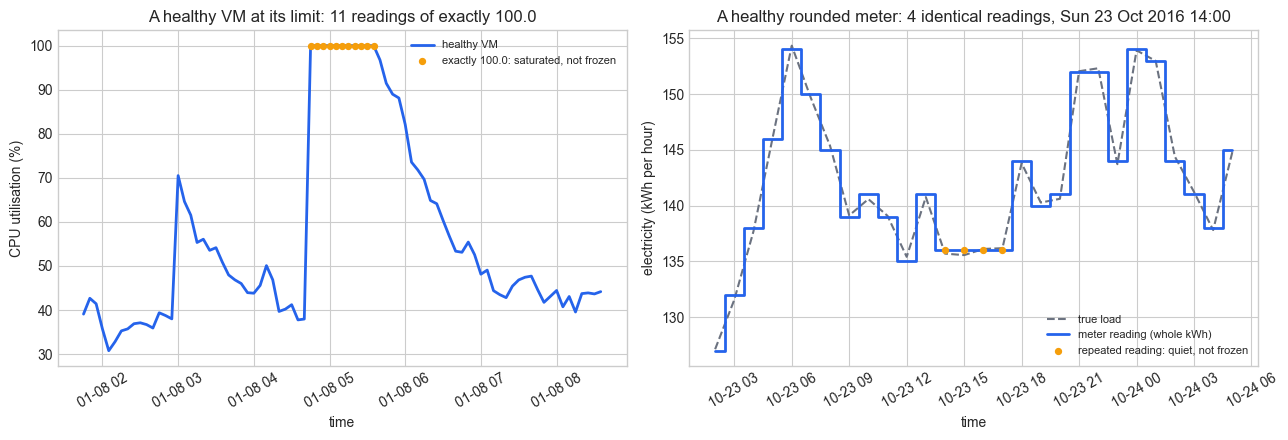

In [9]:
# Two innocent flat lines: the longest healthy saturation run, and the longest innocent
# repeat on the rounded meter.
k_sat = int(np.argmax(sat_lengths))
meter_starts, meter_lengths = episodes(flag_stuck_runs(load_rounded, 2))
k_meter = int(np.argmax(meter_lengths))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
s, n = sat_starts[k_sat], sat_lengths[k_sat]
win = slice(s - 36, s + n + 36)
axes[0].plot(cpu_true.index[win], cpu_true.iloc[win], color=BLUE, linewidth=2, label="healthy VM")
axes[0].scatter(cpu_true.index[s:s + n], cpu_true.iloc[s:s + n], color=AMBER, s=18, zorder=3,
                label="exactly 100.0: saturated, not frozen")
axes[0].set_title(f"A healthy VM at its limit: {n} readings of exactly 100.0")
axes[0].set_ylabel("CPU utilisation (%)")

s, n = meter_starts[k_meter] - 1, meter_lengths[k_meter] + 1   # include the run's first reading
win = slice(s - 12, s + n + 12)
axes[1].plot(load_true.index[win], load_true.iloc[win], color=GRAY, linestyle="--", linewidth=1.5,
             label="true load")
axes[1].step(load_rounded.index[win], load_rounded.iloc[win], where="mid", color=BLUE, linewidth=2,
             label="meter reading (whole kWh)")
axes[1].scatter(load_rounded.index[s:s + n], load_rounded.iloc[s:s + n], color=AMBER, s=18, zorder=3,
                label="repeated reading: quiet, not frozen")
axes[1].set_title(f"A healthy rounded meter: {n} identical readings, "
                  f"{load_rounded.index[s]:%a %d %b %Y %H:%M}")
axes[1].set_ylabel("electricity (kWh per hour)")
for ax in axes:
    ax.set_xlabel("time")
    ax.tick_params(axis="x", rotation=30)
    ax.legend(loc="best", fontsize=8)
plt.tight_layout()
plt.show()

Both panels show healthy data that a short-L rule would flag. On the left, a burst drives
the VM to its ceiling: 11 consecutive readings of exactly 100.0 before the load decays. Keep
this run in mind, because it reappears in the next cell. On the right, the rounded meter
reports four identical readings on a quiet Sunday afternoon while the true load (gray) wobbles
by a fraction of a kWh underneath; whole-kWh resolution simply cannot see the wobble. Neither
is a fault, and a rule that flags them teaches the on-call engineer to ignore the rule.

In [10]:
# Guards, scored on the contaminated series. Guard 1: a longer L. Guard 2: ignore readings
# sitting exactly at a physical limit (0% and 100% CPU) - saturation cannot be told apart
# from a freeze by this column alone, so we stop trying.
cpu_obs_values = cpu_obs.to_numpy()
at_physical_limit = np.isin(cpu_obs_values, [0.0, 100.0])
load_rounded_obs = load_obs.round()      # the rounded meter, behind the same failing gateway

rows = []
for L in (4, 12):
    flags = flag_stuck_runs(cpu_obs_values, L)
    rows.append({"series": "VM", "rule": f"L = {L}", **precision_recall(flags, cpu_frozen)})
    rows.append({"series": "VM", "rule": f"L = {L}, ignore 0 and 100",
                 **precision_recall(flags & ~at_physical_limit, cpu_frozen)})
for L in (2, 3, 4, 5):
    rows.append({"series": "rounded meter", "rule": f"L = {L}",
                 **precision_recall(flag_stuck_runs(load_rounded_obs, L), load_frozen)})
guards = pd.DataFrame(rows).set_index(["series", "rule"])

missed = cpu_frozen & ~(flag_stuck_runs(cpu_obs_values, 4) & ~at_physical_limit)
m_starts, m_lengths = episodes(missed)
for s, n in zip(m_starts, m_lengths):
    print(f"the limit guard misses {n} frozen VM readings from {cpu_obs.index[s]:%a %d %b %H:%M}, "
          f"frozen at {cpu_obs_values[s]:.1f}%")
guards.round(3)

the limit guard misses 23 frozen VM readings from Tue 08 Jan 04:50, frozen at 100.0%


flagged  precision  recall
series        rule                                                
VM            L = 4                         638      0.925   1.000
              L = 4, ignore 0 and 100       567      1.000   0.961
              L = 12                        541      1.000   0.917
              L = 12, ignore 0 and 100      518      1.000   0.878
rounded meter L = 2                        2147      0.633   1.000
              L = 3                        1462      0.930   1.000
              L = 4                        1364      0.994   0.997
              L = 5                        1355      0.999   0.995

The limit guard buys perfect precision on the VM at any L, and its price is printed above the
table: one episode of 23 readings from Tuesday 8 January at 04:50, frozen at 100.0%. It is the
saturation run from the left panel above. The VM hit its ceiling at 04:45, and five minutes
later the agent froze on that value, so the reported series shows 100.0 for two hours, from
04:45 to 06:40, where the healthy VM came off its ceiling after 55 minutes. By the CPU column alone, that freeze
is indistinguishable from a long burst; the guard waves it through and recall drops from 1.000
to 0.961. On the rounded meter the trade-off lives entirely in L: L = 2 flags 2,147 readings at
precision 0.633 (more than one flag in three is a quiet night), L = 4 reaches 0.994 precision
at 0.997 recall, and L = 5 is cleaner still (0.999) at the cost of the shortest freezes.

No guard is free. The menu, with the bill attached:

| Guard | What it does | What it costs (the pitfall) |
|---|---|---|
| Longer L | ignores flat lines shorter than L readings | misses short freezes: VM recall 0.917 at L = 12 |
| Ignore physical limits (0%, 100%, a feeder at 0 kWh) | removes saturation and switched-off false flags | blind to a freeze that happens at the limit, like the 8 January episode |
| L from healthy history (just above the longest innocent run per meter) | adapts L to each meter's resolution and behaviour | needs a clean history per device; a firmware update can change the resolution |
| Several columns at once (min, max and average CPU, memory, network, a sequence counter) | a stuck relay repeats every column it forwards; a saturated VM pins its CPU columns while memory and network keep moving | needs the extra columns; some datasets publish only one (the Azure traces publish min, max and average CPU) |
| Physics cross-check (temperature swings, load does not) | HVAC load must react to a large temperature change | needs a model; weekends and holidays are legitimately flat |

For the rest of this notebook we ship the simplest defensible pair: L = 4 for the building
(safe even if the meter rounds) and L = 4 with the limit guard for the VM. One property of the
rule matters as soon as it runs live rather than on a finished series: it cannot flag a flat
line before the line is L readings long, and the first of those readings is genuine, so with
L = 4 the first flag falls on the third frozen reading. Section 4 measures that delay.

## 4. What frozen data does to the metrics

Detection was half the job. The other half is the question the facilities lead actually
asked: how many of our good numbers are made of frozen data, and would they change if we took
it out? We answer it with notebook 11's protocol (walk-forward blocks, a refit before every
block, calibration on the rows just before the block, an h-row purge) and the same CQR recipe
as notebook 12, without its quantile-crossing repair, run three times on the same observed
series:

| Pipeline | Trains and calibrates on | What it stands for |
|---|---|---|
| raw | every row | the project that never looked for freezes |
| gated | the rows the minimum-run-length rule leaves unflagged | the project that ran this notebook's rule |
| oracle-gated | the rows that are truly clean | the ceiling: a perfect detector, available only in simulation |

Four decisions make the comparison precise.

- **Which rows are dirty.** A row of the forecasting table is dirty when the reading it
  predicts (the target) or the reading it starts from (the forecast origin) is flagged.
  Frozen readings deeper in the feature window, such as yesterday's value at the target hour,
  are left in: every frozen hour sits in the feature window of dozens of rows (through the
  trailing daily mean and the 14 same-hour lags), so dropping every row a freeze reaches would
  throw away far more of the table than the freezes themselves occupy.
- **Which gates.** The building gate is L = 4, safe for a meter that rounds to whole kWh
  (section 3) at a recall of 0.997 on this float meter. The VM gate is L = 4 with the
  physical-limit guard: precision 1.000, recall 0.961.
- **Every pipeline forecasts every test row.** A gate decides what the model learns from and
  calibrates on, not which forecasts get issued. Evaluation then reports unflagged and flagged
  test rows separately, using the gate's flags for all three pipelines, so the pipelines are
  always compared on identical rows.
- **Two yardsticks.** We score against the observed values (what the sensor reported, the only
  thing a real project can score against) and against the true values (what the building or VM
  actually did). The second yardstick is a simulation luxury: in a real project the true value
  behind a frozen reading is gone for good, and that column cannot be computed.

Horizons are h = 1 and h = 24 for the building (next hour, day ahead) and h = 1 and h = 12 for
the VM (5 minutes, 1 hour), on the protocol constants every Part II notebook uses. Before
running anything, write down what could happen. A frozen target is a copy of the reading before
it, so persistence predicts it perfectly: dirty evaluation should flatter the last-value
baseline. Frozen calibration rows might be just as easy for the model, give tiny scores and
shrink the band. Or neither: the gate may improve accuracy, coverage only, or nothing at all,
and we report what we find.

In [11]:
def walk_forward_cqr_gated(tab, features, keep_by_pipeline, h, first_test_row, block_len, cal_len):
    """Notebook 12's walk-forward CQR recipe (without its quantile-crossing repair), each
    pipeline trained and calibrated on its kept rows only.

    `keep_by_pipeline` maps a pipeline name to a boolean array over table rows; rows marked
    False are dropped from training AND calibration. Every pipeline still forecasts every
    test row: a gate decides what the model learns from, not which origins get a forecast.
    Returns {pipeline: (test_frame, cal_frame)}. test_frame holds, per test row, the band
    (`lo`, `mid`, `hi`), the block's `q_hat` and calibration size, and `raw_score`, the CQR
    score against the uncorrected quantiles. cal_frame holds the CQR score of every row in
    each calibration window, kept or not (the theory touch below reuses it).
    """
    X, y = tab[features].to_numpy(), tab["target"].to_numpy()
    out = {}
    for name, keep in keep_by_pipeline.items():
        test_parts, cal_parts = [], []
        for block, (train, cal, test) in enumerate(
                walk_forward_blocks(len(tab), first_test_row, block_len, cal_len, h)):
            train = train[keep[train]]                      # the gate acts on training rows...
            lo_m, mid_m, hi_m = (quantile_gbm(q).fit(X[train], y[train])
                                 for q in (ALPHA / 2, 0.5, 1 - ALPHA / 2))
            cal_scores = np.maximum(lo_m.predict(X[cal]) - y[cal], y[cal] - hi_m.predict(X[cal]))
            q_hat = corrected_quantile(cal_scores[keep[cal]], ALPHA)   # ...and on calibration rows
            lo, hi = lo_m.predict(X[test]), hi_m.predict(X[test])
            test_parts.append(pd.DataFrame({
                "block": block, "lo": lo - q_hat, "mid": mid_m.predict(X[test]), "hi": hi + q_hat,
                "q_hat": q_hat, "n_cal": int(keep[cal].sum()),
                "raw_score": np.maximum(lo - y[test], y[test] - hi)}, index=test))
            cal_parts.append(pd.DataFrame({"block": block, "score": cal_scores}, index=cal))
        out[name] = (pd.concat(test_parts), pd.concat(cal_parts))
    return out


def shipped_gate(values, family):
    """The gates chosen in section 3: L = 4 everywhere, plus the physical-limit guard on CPU."""
    values = np.asarray(values, dtype=float)
    flags = flag_stuck_runs(values, 4)
    if family == "VM":
        flags &= ~np.isin(values, [0.0, 100.0])
    return flags


def live_first_flag(values, frozen, family):
    """Run the gate live: for each freeze, readings from onset to its first flag (None if never).

    Live, the rule sees only the readings so far, so it cannot flag a flat line before the line
    is L readings long. Each check runs the gate on the series up to reading t and no further.
    """
    values = np.asarray(values, dtype=float)
    return [next((t - s for t in range(s, s + n) if shipped_gate(values[:t + 1], family)[t]), None)
            for s, n in zip(*episodes(frozen))]


load_gate = shipped_gate(load_obs, "building")
cpu_gate = shipped_gate(cpu_obs, "VM")

# Protocol constants shared by every Part II notebook. Temperature at the target hour is
# treated as a known weather forecast for the building, as in notebooks 11 and 12.
FAMILIES = {
    "building": dict(obs=load_obs, true=load_true, frozen=load_frozen, gate=load_gate,
                     minutes_per_reading=60, period=24, exog=b["temp_c"], features=MODEL_FEATURES + ["exog_at_target"],
                     horizons=(1, 24), test_rows=24 * 7 * 24, block_len=24 * 28, cal_len=24 * 28),
    "VM": dict(obs=cpu_obs, true=cpu_true, frozen=cpu_frozen, gate=cpu_gate,
               minutes_per_reading=5, period=288, exog=None, features=MODEL_FEATURES,
               horizons=(1, 12), test_rows=288 * 8, block_len=288 * 2, cal_len=288),
}

runs = {}
t_all = time.time()
for family, f in FAMILIES.items():
    delay = pd.Series(live_first_flag(f["obs"], f["frozen"], family), dtype=float)
    lags = sorted(delay.dropna().astype(int).unique())
    print(f"{family}: run live, the gate flags {delay.notna().sum()} of {len(delay)} freezes, each first "
          f"flagged {' or '.join(map(str, lags))} readings after onset "
          f"({' or '.join(str(lag * f['minutes_per_reading']) for lag in lags)} min); "
          f"{delay.isna().sum()} never flagged")
    for h in f["horizons"]:
        t0 = time.time()
        tab = make_direct_table(f["obs"], h, f["period"], exog=f["exog"])   # observed data only
        origin = f["obs"].index.get_indexer(tab.index)
        flagged = f["gate"][origin] | f["gate"][origin + h]                 # the gate's view
        truly_dirty = f["frozen"][origin] | f["frozen"][origin + h]         # the simulation's view
        first_test_row = len(tab) - f["test_rows"]
        pipelines = {"raw": np.ones(len(tab), dtype=bool), "gated": ~flagged}
        gate_is_perfect = np.array_equal(flagged, truly_dirty)
        if not gate_is_perfect:
            pipelines["oracle"] = ~truly_dirty
        preds = walk_forward_cqr_gated(tab, f["features"], pipelines, h, first_test_row,
                                       f["block_len"], f["cal_len"])
        if gate_is_perfect:              # identical rows give identical models: reuse, do not refit
            preds["oracle"] = preds["gated"]
        runs[(family, h)] = dict(tab=tab, preds=preds, flagged=flagged, truly_dirty=truly_dirty,
                                 y_true=f["true"].to_numpy()[origin + h])
        # The flags above are retrospective: each run is judged by its full length. A causal gate
        # sees only the readings up to each block's first forecast origin. Which calibration rows
        # would it judge differently?
        n_cal_rows, n_changed = 0, 0
        for _, cal, test_block in walk_forward_blocks(len(tab), first_test_row, f["block_len"],
                                                      f["cal_len"], h):
            live = shipped_gate(f["obs"].to_numpy()[:origin[test_block[0]] + 1], family)
            n_changed += int(((live[origin[cal]] | live[origin[cal] + h]) != flagged[cal]).sum())
            n_cal_rows += len(cal)
        test = np.arange(first_test_row, len(tab))
        unflagged = test[~flagged[test]]
        print(f"{family} h={h}: {flagged.mean():.1%} of {len(tab):,} rows flagged "
              f"({truly_dirty.mean():.1%} truly dirty); "
              f"oracle {'reused (gate = truth on every row)' if gate_is_perfect else 'refitted'} "
              f"[{time.time() - t0:.0f} s]")
        print(f"   test period: {flagged[test].sum()} of {len(test):,} rows flagged; gate agrees with the "
              f"truth on {np.mean(flagged[test] == truly_dirty[test]):.1%} of test rows; unflagged rows where "
              f"observed != true: {int((tab['target'].to_numpy()[unflagged] != f['true'].to_numpy()[origin[unflagged] + h]).sum())}")
        print(f"   whole table: gate and truth disagree on {int((flagged != truly_dirty).sum())} rows; a causal "
              f"gate would change {n_changed} of {n_cal_rows:,} calibration rows")
print(f"all pipelines, 4 family-horizons, refit before every block: {time.time() - t_all:.0f} s")

building: run live, the gate flags 78 of 80 freezes, each first flagged 2 readings after onset (120 min); 2 never flagged


building h=1: 8.3% of 17,184 rows flagged (8.4% truly dirty); oracle refitted [6 s]
   test period: 305 of 4,032 rows flagged; gate agrees with the truth on 100.0% of test rows; unflagged rows where observed != true: 0
   whole table: gate and truth disagree on 6 rows; a causal gate would change 1 of 4,032 calibration rows


building h=24: 15.0% of 17,184 rows flagged (15.0% truly dirty); oracle refitted [5 s]
   test period: 560 of 4,032 rows flagged; gate agrees with the truth on 100.0% of test rows; unflagged rows where observed != true: 0
   whole table: gate and truth disagree on 6 rows; a causal gate would change 0 of 4,032 calibration rows
VM: run live, the gate flags 29 of 30 freezes, each first flagged 2 readings after onset (10 min); 1 never flagged


VM h=1: 9.4% of 4,608 rows flagged (9.4% truly dirty); oracle reused (gate = truth on every row) [2 s]
   test period: 189 of 2,304 rows flagged; gate agrees with the truth on 100.0% of test rows; unflagged rows where observed != true: 0
   whole table: gate and truth disagree on 0 rows; a causal gate would change 0 of 1,152 calibration rows


VM h=12: 13.7% of 4,608 rows flagged (13.7% truly dirty); oracle reused (gate = truth on every row) [2 s]
   test period: 275 of 2,304 rows flagged; gate agrees with the truth on 100.0% of test rows; unflagged rows where observed != true: 0
   whole table: gate and truth disagree on 0 rows; a causal gate would change 0 of 1,152 calibration rows
all pipelines, 4 family-horizons, refit before every block: 14 s


Start with the first line of each family, the live detection delay a project report needs.
Run live, the gate flags 78 of the building's 80 freezes and 29 of the VM's 30, each time
exactly 2 readings after onset: 120 minutes on the hourly meter, 10 minutes on the VM. The
misses are the two building freezes only two readings long (a flat line of three, below
L = 4) and the VM freeze at 100%, which the limit guard exempts by design.

Three facts from the rest of the printout shape everything below. First, the share of dirty
rows exceeds the share of frozen readings (7.8% and 6.8%) and grows with the horizon: on the
building it nearly doubles, from 8.3% at h = 1 to 15.0% at h = 24; on the VM it rises by about
half, from 9.4% to 13.7%. A row is dirty when its target or its origin is frozen. At h = 1 an
episode of L frozen readings dirties L + 1 neighbouring rows; at a longer horizon it dirties the
L rows that predict a frozen reading and the L rows that start from one, close to 2L when the
freeze is shorter than the horizon and fewer when it is longer, because then some rows start and
end inside the same freeze. Most VM freezes outlast 12 readings, hence its smaller rise. The
further ahead you forecast, the more of the table a freeze reaches, and the more calibration
rows the gate removes.

Second, the gates are essentially the oracle. In the test period the gate agrees with the truth
on 100.0% of test rows in all four settings, and on every unflagged test row the observed value
equals the true one, so the `unflagged rows` columns below need only one yardstick. On the VM
the gate equals the truth on every row of the table, because the one episode the limit guard
misses (8 January) falls in the first 14 days, which the 14-day features consume before the
table begins; the oracle was therefore reused rather than refitted. On the building, gate and
truth disagree on 6 rows of the table, a few of them in the first block's calibration window,
which is why the band table below shows 621.667 against 621.167 calibration rows and a
`q_hat` of 1.002 against 1.025 at h = 1. Whatever separates the raw pipeline from the gated one
below is the effect of frozen data, not of detector error.

Third, the flags are retrospective: each run is judged by its full length, including readings
that arrive after a block starts. A causal gate that sees only the readings up to each block's
first forecast origin would change 1 of the 4,032 building calibration rows at h = 1 and none
anywhere else, so no result below depends on the difference.

In [12]:
def mae(y, point):
    return float(np.mean(np.abs(np.asarray(y) - np.asarray(point))))


rows = []
for (family, h), r in runs.items():
    tab, flagged, y_true = r["tab"], r["flagged"], r["y_true"]
    y_obs = tab["target"].to_numpy()
    test = r["preds"]["raw"][0].index.to_numpy()
    unflagged, flag_rows = test[~flagged[test]], test[flagged[test]]
    forecasts = {"persistence": tab["last_value"].to_numpy()}
    for name in ("raw", "gated", "oracle"):
        point = np.full(len(tab), np.nan)
        point[test] = r["preds"][name][0]["mid"].to_numpy()
        forecasts[f"GBM, {name}"] = point
    for method, point in forecasts.items():
        rows.append({"family": family, "h": h, "forecaster": method,
                     "all rows vs observed": mae(y_obs[test], point[test]),
                     "all rows vs true": mae(y_true[test], point[test]),
                     "unflagged rows": mae(y_obs[unflagged], point[unflagged]),
                     "flagged vs observed": mae(y_obs[flag_rows], point[flag_rows]),
                     "flagged vs true": mae(y_true[flag_rows], point[flag_rows])})
    # The question the project exists to answer: how much better than persistence is the model?
    pers, gbm = rows[-4], rows[-3]          # this family-horizon's persistence and raw GBM rows
    print(f"{family} h={h}: raw GBM's margin over persistence - "
          f"{1 - gbm['all rows vs observed'] / pers['all rows vs observed']:.1%} on all rows vs observed, "
          f"{1 - gbm['unflagged rows'] / pers['unflagged rows']:.1%} on unflagged rows")
accuracy = pd.DataFrame(rows).set_index(["family", "h", "forecaster"])
accuracy.round(2)

building h=1: raw GBM's margin over persistence - 43.8% on all rows vs observed, 48.4% on unflagged rows
building h=24: raw GBM's margin over persistence - 58.9% on all rows vs observed, 62.9% on unflagged rows
VM h=1: raw GBM's margin over persistence - 2.1% on all rows vs observed, 6.5% on unflagged rows
VM h=12: raw GBM's margin over persistence - 28.1% on all rows vs observed, 32.6% on unflagged rows


all rows vs observed  all rows vs true  unflagged rows  flagged vs observed  flagged vs true
family   h  forecaster                                                                                               
building 1  persistence                 18.48             24.63           19.66                 3.99            85.27
            GBM, raw                    10.39             15.39           10.14                13.51            79.54
            GBM, gated                  12.11             13.57           10.05                37.20            56.53
            GBM, oracle                 12.23             13.79           10.13                37.87            58.51
         24 persistence                 50.75             47.91           43.27                97.13            76.72
            GBM, raw                    20.86             16.18           16.04                50.73            17.07
            GBM, gated                  21.34             16.70           16.33                52.43            19.01
            GBM, oracle                 21.03             16.35           16.12                51.47            17.78
VM       1  persistence                  2.61              3.03            2.82                 0.24             5.32
            GBM, raw                     2.56              2.78            2.64                 1.64             4.38
            GBM, gated                   2.55              2.80            2.64                 1.60             4.56
            GBM, oracle                  2.55              2.80            2.64                 1.60             4.56
         12 persistence                  8.03              8.28            8.45                 4.95             7.02
            GBM, raw                     5.77              5.74            5.70                 6.33             6.06
            GBM, gated                   5.84              5.82            5.83                 5.89             5.72
            GBM, oracle                  5.84              5.82            5.83                 5.89             5.72

Start with the honest comparison, the `unflagged rows` column, where observed and true values
coincide. The three model pipelines are indistinguishable: 10.14, 10.05 and 10.13 kWh at
building h = 1; 16.04, 16.33 and 16.12 at h = 24; 2.64 for all three at VM h = 1; 5.70, 5.83
and 5.83 at VM h = 12. Those gaps are the size of ordinary refit noise, and in two of the four
settings the raw model is a hair ahead. The gate did not improve accuracy. That is the first finding, and it is
reportable as it stands.

The second finding is the predicted one, and it is real: frozen targets flatter persistence.
On flagged rows scored against observed values, persistence errs by only 3.99 kWh at building
h = 1 and 0.24 points of CPU at VM h = 1, because a frozen target is the previous reading.
Blended into the all-rows number, those freebies make the last-value rule look better than it
is: 18.48 kWh instead of 19.66 at building h = 1, 2.61 instead of 2.82 at VM h = 1. The
printout above the table shows what that does to the question this project exists to answer.
On the VM at h = 1 the model's margin over persistence is 6.5% on unflagged rows and 2.1% on
the blended yardstick: dirty evaluation erases about two-thirds of the model's advantage, and a
2% edge is the kind a reviewer dismisses with "the model did not beat persistence" (field guide
§17). At VM h = 12 the margin shrinks from 32.6% to 28.1%; at building h = 1, where the model
wins by a mile, from 48.4% to 43.8%. At building h = 24 nothing is flattered (few freezes
outlast a day, so the day-old origin is rarely a copy of the target); instead every forecaster
is punished, and the raw model's MAE rises from 16.04 on unflagged rows to 20.86 on all rows.

The third finding is the one nobody predicted. Score the two pipelines on all rows against
observed values at building h = 1 and the raw pipeline wins, 10.39 against 12.11: the gate
seems to have made the model 17% worse. Against the truth on the same rows the order flips,
15.39 against 13.57. The flagged columns explain it. The raw model learned from its dirty
training rows that "the next hour often equals this hour", and on flagged rows it predicts the
freeze (13.51 against observed values, 79.54 against true ones). The gated model never learned
that habit (37.20 and 56.53). Scored against frozen data, the model that learned the fault wins.
What the flagged columns do not show is anyone forecasting well during a freeze: the inputs are
frozen too, and even the better model misses the true load by 56.53 kWh there.

In [13]:
rows = []
for (family, h), r in runs.items():
    tab, flagged, y_true = r["tab"], r["flagged"], r["y_true"]
    y_obs = tab["target"].to_numpy()
    for name in ("raw", "gated", "oracle"):
        p = r["preds"][name][0]
        test = p.index.to_numpy()
        unflagged, flag_rows = test[~flagged[test]], test[flagged[test]]
        u = band_report(y_obs[unflagged], p.loc[unflagged, "mid"], p.loc[unflagged, "lo"],
                        p.loc[unflagged, "hi"], ALPHA)
        lo_f, hi_f = p.loc[flag_rows, "lo"].to_numpy(), p.loc[flag_rows, "hi"].to_numpy()
        rows.append({"family": family, "h": h, "pipeline": name,
                     "calibration rows": p["n_cal"].mean(), "q_hat": p["q_hat"].mean(),
                     "coverage": u["coverage"], "width": u["width"],
                     "interval score": u["interval_score"],
                     "flagged: coverage vs observed": np.mean((y_obs[flag_rows] >= lo_f) & (y_obs[flag_rows] <= hi_f)),
                     "flagged: coverage vs true": np.mean((y_true[flag_rows] >= lo_f) & (y_true[flag_rows] <= hi_f))})
bands = pd.DataFrame(rows).set_index(["family", "h", "pipeline"])
bands.round(3)

calibration rows  q_hat  coverage    width  interval score  flagged: coverage vs observed  flagged: coverage vs true
family   h  pipeline                                                                                                                      
building 1  raw                672.000  0.656     0.899   50.245          62.761                          0.816                      0.449
            gated              621.667  1.002     0.902   45.661          59.449                          0.692                      0.443
            oracle             621.167  1.025     0.900   46.205          59.975                          0.708                      0.436
         24 raw                672.000  4.972     0.921  112.645         128.128                          0.671                      0.880
            gated              580.667  2.838     0.898   67.992          92.058                          0.695                      0.873
            oracle             580.000  3.070     0.899   67.381          90.031                          0.695                      0.870
VM       1  raw                288.000  0.905     0.892   12.657          22.893                          0.963                      0.667
            gated              270.500  0.965     0.899   13.075          23.140                          0.979                      0.672
            oracle             270.500  0.965     0.899   13.075          23.140                          0.979                      0.672
         12 raw                288.000  6.147     0.899   26.816          52.754                          0.920                      0.905
            gated              262.750  6.503     0.912   28.621          52.265                          0.960                      0.927
            oracle             262.750  6.503     0.912   28.621          52.265                          0.960                      0.927

Coverage on unflagged rows stays between 0.892 and 0.921 under every pipeline, and both
extremes are raw: building h = 24 over-delivers at 0.921, VM h = 1 falls short at 0.892. So the
gate did not rescue coverage in any dramatic way either. Where it did act is width. At building
h = 1 the gated band is 45.7 kWh wide against 50.2 raw (9% narrower, interval score 62.8 to
59.4); at h = 24 it is 68.0 against 112.6 (40% narrower, interval score 128.1 to 92.1) at a
coverage of 0.898 instead of an over-delivered 0.921. That is an outcome the introduction's
list did not include: the gate left accuracy and coverage alone and bought a much sharper band,
which only the interval score column reveals (field guide §18).

The predicted mechanism, frozen calibration rows shrinking the band, is not what moved these
bands. At VM h = 1 the raw band is narrower (12.66 against 13.08) and covers clean rows slightly
less (0.892 against 0.899), in the predicted direction, but the `q_hat` column says calibration
is a small part of it: 0.905 against 0.965, so about 0.12 of the 0.42 points of width; the rest
came from training. On the building the band moves the other way, and again mostly not through
calibration. At h = 24 the raw pipeline's calibration step adds 4.97 kWh to each edge and the
gated one 2.84, so calibration explains about 4 of the 45 kWh of extra width. The other 40 kWh
were learned in training: quantile models fitted on stale targets learned that a day-ahead
target can land far from the building's usual profile, and widened their 5th-to-95th percentile
gap for every row. Frozen data can distort the band in either direction (field guide §20), and
in both families here it did so mainly through the training rows; the calibration effect on its
own is isolated by the simulation after the theory touch.

The flagged columns are the inconvenient part. At building h = 1 the raw band covers 0.816 of
the reported values on flagged rows but only 0.449 of the true ones; the VM at h = 1 shows the
same split (0.963 against 0.667). The band covered what the sensor reported, not what the
building did. At h = 24 the pattern reverses: 0.671 of reported values and 0.880 of true ones,
because a day-ahead forecast was mostly issued before the freeze began and follows the
building, not the gateway.

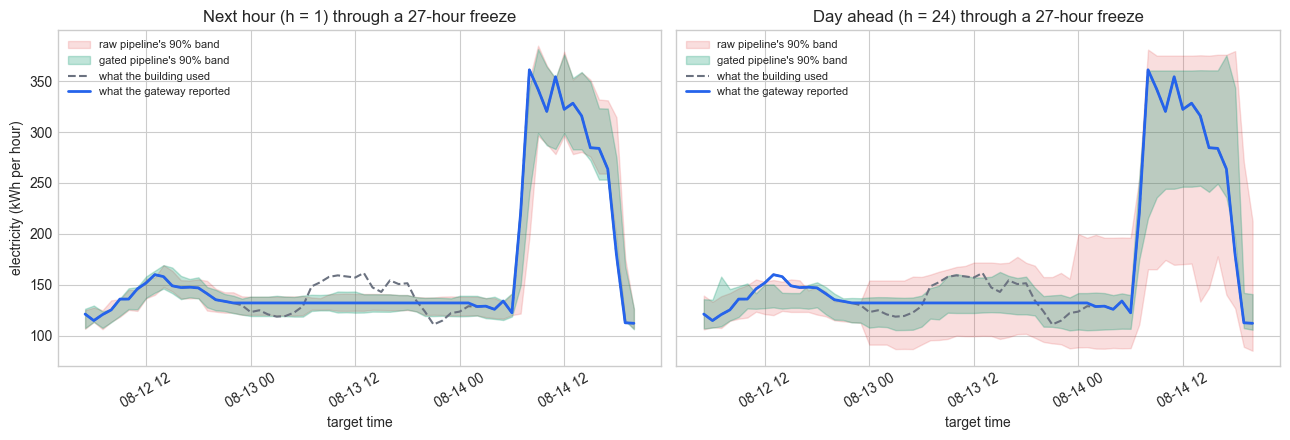

h=1    raw band over the 27 frozen hours from Sat 12 Aug 2017 23:00: covers 100% of reported and 41% of true values, mean width 16.6 kWh
h=1  gated band over the 27 frozen hours from Sat 12 Aug 2017 23:00: covers 100% of reported and 44% of true values, mean width 18.0 kWh
h=24   raw band over the 27 frozen hours from Sat 12 Aug 2017 23:00: covers 100% of reported and 100% of true values, mean width 69.8 kWh
h=24 gated band over the 27 frozen hours from Sat 12 Aug 2017 23:00: covers 100% of reported and 89% of true values, mean width 33.0 kWh


In [14]:
# The longest freeze whose readings fall in the test period, seen by both building horizons.
test_start = runs[("building", 24)]["tab"]["target_time"].iloc[runs[("building", 24)]["preds"]["raw"][0].index[0]]
in_test = np.flatnonzero(load_obs.index[st_b] >= test_start + pd.Timedelta(days=1))
k = in_test[np.argmax(len_b[in_test])]
t0 = load_obs.index[st_b[k]] - pd.Timedelta(hours=18)
t1 = load_obs.index[st_b[k] + len_b[k]] + pd.Timedelta(hours=18)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, h in zip(axes, (1, 24)):
    r = runs[("building", h)]
    p_raw, p_gate = r["preds"]["raw"][0], r["preds"]["gated"][0]
    target_time = r["tab"]["target_time"].iloc[p_raw.index]
    rows_k = p_raw.index[((target_time >= t0) & (target_time <= t1)).to_numpy()]
    t = r["tab"]["target_time"].iloc[rows_k]
    ax.fill_between(t, p_raw.loc[rows_k, "lo"], p_raw.loc[rows_k, "hi"], color=RED, alpha=0.15,
                    label="raw pipeline's 90% band")
    ax.fill_between(t, p_gate.loc[rows_k, "lo"], p_gate.loc[rows_k, "hi"], color=GREEN, alpha=0.25,
                    label="gated pipeline's 90% band")
    ax.plot(t, load_true.loc[t], color=GRAY, linestyle="--", linewidth=1.5, label="what the building used")
    ax.plot(t, load_obs.loc[t], color=BLUE, linewidth=2, label="what the gateway reported")
    ax.set_title(f"{'Next hour' if h == 1 else 'Day ahead'} (h = {h}) through a {len_b[k]}-hour freeze")
    ax.set_xlabel("target time")
    ax.tick_params(axis="x", rotation=30)
    ax.legend(loc="upper left", fontsize=8)
axes[0].set_ylabel("electricity (kWh per hour)")
plt.tight_layout()
plt.show()

frozen_t = load_obs.index[st_b[k]:st_b[k] + len_b[k]]
for h, name in [(1, "raw"), (1, "gated"), (24, "raw"), (24, "gated")]:
    r = runs[("building", h)]
    p = r["preds"][name][0]
    target_time = r["tab"]["target_time"].iloc[p.index]
    sel = p.index[target_time.isin(frozen_t).to_numpy()]
    inside_obs = np.mean((load_obs.loc[frozen_t].to_numpy() >= p.loc[sel, "lo"].to_numpy())
                         & (load_obs.loc[frozen_t].to_numpy() <= p.loc[sel, "hi"].to_numpy()))
    inside_true = np.mean((load_true.loc[frozen_t].to_numpy() >= p.loc[sel, "lo"].to_numpy())
                          & (load_true.loc[frozen_t].to_numpy() <= p.loc[sel, "hi"].to_numpy()))
    width = (p.loc[sel, "hi"] - p.loc[sel, "lo"]).mean()
    print(f"h={h:<2} {name:>5} band over the {len_b[k]} frozen hours from {frozen_t[0]:%a %d %b %Y %H:%M}: "
          f"covers {inside_obs:.0%} of reported and {inside_true:.0%} of true values, mean width {width:.1f} kWh")

The figure puts both horizons on the same 27-hour freeze, which begins on Saturday 12 August
2017 at 23:00: another Saturday, and a longer freeze than G-14's. On the left, both next-hour bands lock onto the frozen value
within an hour and travel with it: the forecaster's inputs are the frozen readings, so its
forecast is "about the same as now", and the band surrounds the flat blue line while the
building's real Sunday load (gray) climbs out of it. The printout scores it: both next-hour
bands cover 100% of the reported values, and only 41% (raw) and 44% (gated) of the true ones. Gating
cleaned what the model learned from; it cannot clean what the model is fed live. This is
notebook 14's "the forecaster chases the fault", seen from the data side.

On the right, the day-ahead forecasts for those hours were issued before the freeze, so both
bands follow the building's usual profile and cover 100% (raw) and 89% (gated) of the true
values, while the frozen report sits inside them only because a quiet Sunday is flat anyway. The raw band (red) is the
width finding of the band table made visible: over the frozen hours it averages 69.8 kWh
wide against 33.0 for the gated band (green), and on the Monday morning after the freeze
the gap opens further.

### Why it happens: the calibration set is a mixture

The corrected quantile makes exactly one promise (notebook 03's leaderboard argument): a new
row that is exchangeable with the calibration rows lands inside the band at least 90% of the
time. A calibration window with frozen rows in it is a mixture of two populations, rows on which
the sensor told the truth and rows on which it repeated itself. The newcomer the promise
protects is a random draw from that same mixture, scored against what the sensor reported. So
the guarantee survives in a precise and nearly useless form: about 90% of reported values,
frozen or not, land inside the band. It promises nothing about the clean rows on their own, and
nothing at all about the truth behind a frozen reading (field guide §20). The 0.449 above is
that second clause, measured.

Which way the clean rows move depends on which way the dirty rows lean. If they are easy
(small scores, comfortably inside the band) they pad the bottom of the leaderboard, the
threshold needs to catch fewer clean rows to reach 90% overall, and the band shrinks. If they
are hard (the jump when a gateway thaws, the stale target a day-ahead model did not expect)
they crowd the top, and the band inflates.

The same statement in symbols. Write $\pi$ for the share of dirty rows in the calibration
window, $F_c(q)$ and $F_d(q)$ for the share of clean and of dirty scores at or below a
threshold $q$, and $1 - \alpha = 0.90$ for the target. The calibrated threshold makes the
mixture cover about 90%, $(1 - \pi) F_c(q) + \pi F_d(q) \approx 1 - \alpha$, so the clean
rows get

$$F_c(q) \approx \frac{1 - \alpha - \pi F_d(q)}{1 - \pi}.$$

If every dirty row is easy, $F_d(q) = 1$ and clean coverage sinks to
$(1 - \alpha - \pi)/(1 - \pi)$; if every dirty row is hard, $F_d(q) = 0$ and it rises to
$(1 - \alpha)/(1 - \pi)$. At the roughly 8% dirty share of our building at h = 1, clean
coverage could land anywhere from 0.891 to 0.978 without the theorem being violated. The same
logic applies one step earlier, in training: quantile models fitted on a mixture learn the
mixture's percentiles, which is how the raw building bands came out wide before calibration
even started.

Simulation beats proof. The next cell keeps the clean-trained (gated) models fixed, varies
only the share of dirty rows in the calibration window from 0 to 40%, and measures coverage on
truly clean test rows.

building h=1: 69.2% of dirty calibration rows fall inside the clean-calibrated band
building h=24: 69.6% of dirty calibration rows fall inside the clean-calibrated band
      VM h=1: 98.6% of dirty calibration rows fall inside the clean-calibrated band
     VM h=12: 92.1% of dirty calibration rows fall inside the clean-calibrated band


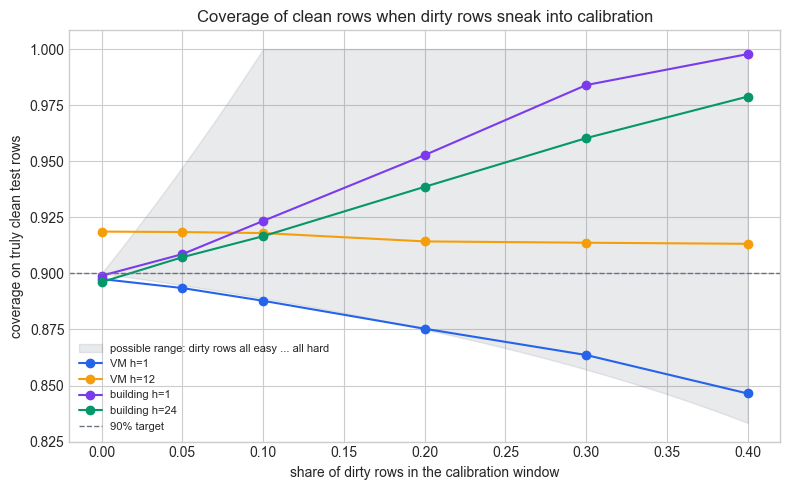

series,VM h=1,VM h=12,building h=1,building h=24
dirty share of calibration,,,,
0.00,0.897,0.919,0.899,0.896
0.05,0.893,0.918,0.909,0.907
0.10,0.888,0.918,0.923,0.917
0.20,0.875,0.914,0.953,0.939
0.30,0.864,0.914,0.984,0.960
0.40,0.846,0.913,0.998,0.979


In [15]:
# Keep the clean-trained (gated) models fixed and vary ONLY the calibration set: draw
# calibration windows with a chosen share of dirty rows, recompute the corrected quantile,
# and measure coverage on truly clean test rows. 300 draws per share, pooled over blocks.
rng = np.random.default_rng(RANDOM_SEED)
shares = [0.0, 0.05, 0.10, 0.20, 0.30, 0.40]
mix_rows, lean = [], {}
for (family, h), r in runs.items():
    p, cal = r["preds"]["gated"]
    dirty = r["truly_dirty"]
    clean_pool = cal.loc[~dirty[cal.index], "score"].to_numpy()
    dirty_pool = cal.loc[dirty[cal.index], "score"].to_numpy()
    test = p.index.to_numpy()
    clean_test_scores = p.loc[test[~dirty[test]], "raw_score"].to_numpy()
    n = FAMILIES[family]["cal_len"]
    # Which way do the dirty rows lean? Share of them inside the clean-calibrated band.
    lean[f"{family} h={h}"] = np.mean(dirty_pool <= corrected_quantile(clean_pool, ALPHA))
    for share in shares:
        k = int(round(share * n))
        cover = [np.mean(clean_test_scores <= corrected_quantile(
                     np.concatenate([rng.choice(clean_pool, n - k), rng.choice(dirty_pool, k)]), ALPHA))
                 for _ in range(300)]
        mix_rows.append({"dirty share of calibration": share, "series": f"{family} h={h}",
                         "clean-row coverage": np.mean(cover)})
mixture = pd.DataFrame(mix_rows).pivot(index="dirty share of calibration", columns="series",
                                       values="clean-row coverage")
for name, inside in lean.items():
    print(f"{name:>12}: {inside:.1%} of dirty calibration rows fall inside the clean-calibrated band")

fig, ax = plt.subplots(figsize=(8, 5))
grid = np.linspace(0, 0.4, 41)
ax.fill_between(grid, (1 - ALPHA - grid) / (1 - grid), np.minimum((1 - ALPHA) / (1 - grid), 1.0),
                color=GRAY, alpha=0.15, label="possible range: dirty rows all easy ... all hard")
for color, name in zip([BLUE, AMBER, PURPLE, GREEN], mixture.columns):
    ax.plot(mixture.index, mixture[name], marker="o", color=color, label=name)
ax.axhline(1 - ALPHA, color=GRAY, linestyle="--", linewidth=1, label="90% target")
ax.set_title("Coverage of clean rows when dirty rows sneak into calibration")
ax.set_xlabel("share of dirty rows in the calibration window")
ax.set_ylabel("coverage on truly clean test rows")
ax.legend(loc="lower left", fontsize=8)
plt.tight_layout()
plt.show()
mixture.round(3)

The printout says which way each family leans before the curves do. Only 69.2% of the
building's dirty calibration rows at h = 1 (69.6% at h = 24) fall inside a band calibrated on
clean rows: they are hard, mostly thaw jumps and frozen hours during which the real profile
moved. On the VM at h = 1, 98.6% fall inside: a frozen 5-minute reading equals the reading
before it, which is where a 5-minute forecast sits anyway. At VM h = 12 the share is 92.1%,
close to the 90% that makes a dirty row neutral.

The curves follow. Building h = 1 climbs from 0.899 with no dirty rows to 0.923 at 10%, 0.953 at
20% and 0.998 at 40%: hard dirty rows inflate the band until it covers nearly every clean row.
Building h = 24 does the same, more slowly (0.896, 0.917, 0.939, 0.979). VM h = 1 falls, 0.897
to 0.888 at 10%, 0.875 at 20% and 0.846 at 40%: the shrink predicted at the start of section 4, and it hugs
the lower edge of the gray range because its dirty rows are almost all easy. VM h = 12 barely moves (0.919 to 0.913). The starting points are not
exactly 0.90, because pooled test rows are not a perfect match for pooled calibration rows
(VM h = 12 starts at 0.919), but from there every curve moves the way the formula says, inside
the range or on its edge: VM h = 1 dips a hair below the lower edge at 5% and 10% dirty rows
(0.893 against 0.895, 0.888 against 0.889) only because it starts at 0.897 rather than 0.900. Two cautions on
reading it. At our gateways' contamination, 8% to 15% of table rows, the calibration effect
alone is one or two points of coverage; it takes a much dirtier device to move it by five. And this cell isolates calibration on purpose: the larger building effect in
section 4 came through training.

## 5. A gate policy

Everything above reduces to one rule per stage of the pipeline. The gate is the
minimum-run-length rule with the guards from section 3; "flagged row" means its target or its
origin is flagged.

| Stage | Policy | Why (this notebook's evidence) | What it costs |
|---|---|---|---|
| Training | drop flagged rows | the raw model learned to predict the freeze, and its quantile heads learned the thaw jumps as noise: building h = 24 band 112.6 kWh raw against 68.0 gated | a few percent of rows; a missed freeze stays in |
| Calibration | drop flagged rows | the guarantee covers the population you calibrate on; dirty rows lean hard (building, band inflates) or easy (VM, band shrinks) | the window shrinks, 672 to about 581 rows at building h = 24; keep it large enough for the corrected quantile (field guide §1, §4) |
| Evaluation | report unflagged rows as the headline and flagged rows separately, never one blended number | blending flattered persistence (VM h = 1 margin 6.5% down to 2.1%) and ranked the raw pipeline ahead of the gated one when the truth said the opposite | two numbers instead of one, and a sentence explaining why |
| Live monitoring | run the rule on incoming data; on a flag, raise a data-quality alarm and mark forecasts built from frozen inputs as unreliable | the next-hour band chases a freeze (the gated one covered 100% of reported and 44% of true values through a 27-hour weekend freeze), so band-edge alarms catch freezes only where a strong rhythm contradicts them (notebook 14, field guide §21) | one more alarm stream, with its own false-alarm rate per reading and per event (section 3); the first flag arrives 2 readings after onset, 2 hours on the building and 10 minutes on the VM |

Two things the policy deliberately does not do. It does not impute frozen readings with
forecasts and train on the result; that teaches the model its own opinions. And it does not
suppress the flagged rows from the report. They are the answer to the facilities lead's
question, so they get their own column.

## 6. Common mistakes to avoid

1. **Trusting the data-quality dashboard.** Missing-value, range and schedule checks all passed
   (0, 0, 0) on series that were wrong about one reading in thirteen. Add a run-length check;
   it asks the one question the others never ask, whether the value is new (field guide §20).
2. **Exact equality on floats.** `tol = 0` missed a run of three readings that all print as
   0.3. Use a small tolerance, and keep it small: a large one chains a slow genuine drift into
   a false run.
3. **A short L on saturating or rounded sensors.** At L = 2 a healthy VM raises 2.8 false
   flags a day (1.07 events) and a whole-kWh meter 1.2, about 3,500 flags a day across 3,000
   meters. Set L above
   the longest innocent run in healthy history, add physical-limit guards, and remember the
   guard's blind spot: a freeze at 100% looks exactly like saturation.
4. **Scoring against frozen data.** A frozen target is the previous reading, so persistence
   gets it free: the model's margin over persistence fell from 6.5% to 2.1% on the VM at h = 1,
   and the raw pipeline outranked the gated one at building h = 1 (10.39 against 12.11) while the
   truth said the opposite (15.39 against 13.57). Report unflagged and flagged rows separately
   (field guide §17).
5. **Judging the gate by MAE and coverage alone.** The gate changed neither (10.14 against
   10.05 kWh; coverage between 0.892 and 0.921 throughout); what it changed was the building's day-ahead band,
   40% narrower at near-target coverage (0.898 against an over-delivered 0.921). Only the interval score shows that (field guide §18).
6. **Quoting the guarantee for the truth behind frozen rows.** The next-hour band covered 0.816
   of reported values on flagged rows and 0.449 of true ones. The guarantee is about what the
   sensor reported, and only holds for rows exchangeable with the calibration rows (field
   guide §6, §20).

## 7. What to say in the project report

**Strong version**

> "We screened both series for stuck values with a minimum-run-length rule (4 consecutive
> readings equal within 1e-6; CPU readings at exactly 0% or 100% are exempt, since saturation
> is legitimate). In a simulation with a known fault mask the rule recovered 99.7% of frozen
> building readings and 96.1% of frozen CPU readings with no false flags; the one missed CPU
> episode froze at 100%, where the rule cannot tell a freeze from saturation. Run live, the
> rule raises its first flag two readings after a freeze begins: 2 hours on the hourly meter,
> 10 minutes on CPU. Removing flagged
> rows from training and calibration left accuracy unchanged (building next-hour MAE 10.14
> against 10.05 kWh) and coverage near 90%, but narrowed the building's day-ahead band from
> 112.6 to 68.0 kWh (interval score 128.1 to 92.1). All metrics are reported on unflagged rows,
> with flagged rows separately: blending them would have shrunk the model's margin over
> persistence on CPU at the 5-minute horizon from 6.5% to 2.1%. Coverage refers to reported
> values; on frozen rows the next-hour band covered only 44% of the true building load."

**Weak version**

> "We removed bad data before training. The model achieves 90% coverage and beats
> persistence."

The weak version does not say what "bad" means, how much was removed, or what removing it
changed, so a reader cannot tell whether the cleaning mattered. "90% coverage" names neither
the rows nor the yardstick, and on frozen rows the true figure was 44%. "Beats persistence"
hides the size of the win, which on the CPU series depends entirely on whether frozen rows
were scored: 6.5% or 2.1%. The strong version gives the rule, its measured precision and
recall, its known blind spot, the effect of the gate on each metric, and the clause that limits
the guarantee.

### The one-line summary

A frozen gateway passes every check that asks whether data arrived and fails the only one that
asks whether it is new. A few lines of numpy find it, at a price set by the innocent flat lines
of your own sensors, and removing what they find left our forecasts' accuracy untouched while
reshaping the bands and changing which pipeline, and which baseline, looked best. That is why
the gate belongs in the protocol and the flagged rows belong in a column of their own.

A sensor that never changes its mind is not confident, it is broken.